# From selected MC particles to hits on tracking layers

This notebook demonstrates the standalone **`mc_tracking_hits.py`** reader on
one pion simulation file. Copy that module and this notebook together to share
the example; edit the input path below. No other project files, ROOT, PODIO or
DD4hep libraries are needed.

On this machine select **EIC 26.08 (RSU maps)**, then **Run All**. Elsewhere use
Python 3.9+ with NumPy, Awkward Array, Uproot, pandas, Matplotlib and IPython.
The saved example reads only 2,000 events, without changing the ROOT file.

The tables contain **simulated hits directly linked to the selected MC particle**,
not reconstructed hits or fitted-track measurements. A missing hit is not a
geometric intersection test. Primary selection means `generatorStatus == 1`;
secondary ancestry is not folded into the primary.


In [1]:
from pathlib import Path
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})

# Works from either the notebook folder or the workspace root.
MODULE_DIR = next(path for path in (Path.cwd(), Path.cwd()/'scripts')
                  if (path/'mc_tracking_hits.py').is_file())
sys.path.insert(0, str(MODULE_DIR))
from mc_tracking_hits import KEY, SURFACE_KEY, read_mc_tracking_hits, iter_mc_tracking_hits
print('Python:', sys.version.split()[0])


Python: 3.13.13


## 1. Input and MC selection

Cuts use the **MC momentum at production**, not the momentum stored in a hit.
Ranges are half-open `[low, high)`; momentum is in GeV. Set either range to
`None` to remove that cut. `collections=None` discovers all owning tracker-hit
collections. Set `primary_only=False` in the reader call to include secondary MC
particles as well; there is no one-particle-per-event assumption.

The default sample is 5 GeV pi+ with generated eta = 0.9–1.0. A missing L2 hit
in this forward-going sample is possible and is kept in the counting tables.


In [ ]:
ROOT_FILE = Path('path/to/your/file.root')  # Adjust to your ROOT file path.
STOP_EVENTS = 2000             # Keep small for exploration; None reads the whole file.
STEP_SIZE = 1000
ETA_RANGE = (0.9, 1.0)
P_RANGE_GEV = (4.5, 5.5)
PDGS = [211, -211]
COLLECTIONS = None

# VertexBarrel IDs in this production geometry. Inspect the catalogue below
# before using another geometry: layer numbers are not globally unique.
IB_COLLECTION, IB_SYSTEM = 'VertexBarrelHits', 31
LAYER_IDS = [0, 1, 2]
MC_ROW = 0                    # Position in the selected particle table, not an MC index.

assert ROOT_FILE.is_file(), ROOT_FILE
started = time.perf_counter()
tables = read_mc_tracking_hits(ROOT_FILE, collections=COLLECTIONS, primary_only=True,
    pdgs=PDGS, eta_range=ETA_RANGE, p_range=P_RANGE_GEV,
    stop=STOP_EVENTS, step_size=STEP_SIZE)
particles, hits = tables['particles'], tables['hits']
elapsed = time.perf_counter()-started
print(f'{len(particles):,} selected MC particles; {len(hits):,} associated hits; {elapsed:.2f} s')
print(f'{(particles.n_hits == 0).sum():,} selected MC particles have no hit in the requested collections')
assert not particles.empty, 'No selected MC particles: adjust the input/ranges and rerun.'


2,000 selected MC particles; 12,105 associated hits; 1.30 s
3 selected MC particles have no hit in the requested collections


## 2. Understand the tables and their join key

`particles` has one row per selected MC particle, **including zero-hit particles**.
`hits` has one row per associated simulated hit, preserving all stored attributes.
They join on `KEY = (file_id, event_entry, mc_index)`:

- `file_id`: ROOT file UUID, separating different simulation files.
- `event_entry`: zero-based entry in that file, separating events.
- `mc_index`: original index in the event's MCParticles collection.

The MC index is not assumed to be zero. MC kinematics are stored once in
`particles`; merge them into `hits` only when a downstream operation needs them.
CellIDs stay exact uint64 integers; the hexadecimal display below is a copy.


In [3]:
print('Join key:', KEY)
print('Units:', tables['metadata']['units'])
display(particles[KEY + ['pdg', 'p_GeV', 'eta', 'phi_rad', 'n_hits']].head())
hit_preview = hits[KEY + ['hit_collection', 'system', 'layer', 'hit_index',
                         'cell_id', 'x_mm', 'y_mm', 'z_mm']].head().copy()
hit_preview['cell_id_hex'] = hit_preview.cell_id.map(lambda value: hex(int(value)))
display(hit_preview)
display(pd.DataFrame({'column': hits.columns, 'dtype': hits.dtypes.astype(str).to_numpy()}))


Join key: ['file_id', 'event_entry', 'mc_index']
Units: momenta/energy GeV; positions/path length mm; times ns; angles rad


,file_id,event_entry,mc_index,pdg,p_GeV,eta,phi_rad,n_hits
0,1160063f-ec9f-4268-a2c5-04f17ab61ee8,0,0,211,5.0,0.958850,-2.426105,5
1,1160063f-ec9f-4268-a2c5-04f17ab61ee8,1,0,211,5.0,0.955128,0.764443,6
2,1160063f-ec9f-4268-a2c5-04f17ab61ee8,2,0,211,5.0,0.974390,-2.121181,8
3,1160063f-ec9f-4268-a2c5-04f17ab61ee8,3,0,211,5.0,0.958934,-0.333522,5
4,1160063f-ec9f-4268-a2c5-04f17ab61ee8,4,0,211,5.0,0.911613,2.763772,5


,file_id,event_entry,mc_index,hit_collection,system,layer,hit_index,cell_id,x_mm,y_mm,z_mm,cell_id_hex
0,1160063f-ec9f-4268-a2c5-04f17ab61ee8,0,0,MPGDBarrelHits,61,0,0,18391293623556706365,-411.602799,-389.605791,630.627643,0xff3b001c0001103d
1,1160063f-ec9f-4268-a2c5-04f17ab61ee8,1,0,MPGDBarrelHits,61,0,0,18392982258668621885,391.923622,409.397370,628.469277,0xff40ffea0001503d
2,1160063f-ec9f-4268-a2c5-04f17ab61ee8,2,0,MPGDBarrelHits,61,0,0,18384255426289012797,-275.446742,-495.097770,644.320836,0xff21fee80001103d
3,1160063f-ec9f-4268-a2c5-04f17ab61ee8,3,0,MPGDBarrelHits,61,0,0,18396924239782428733,533.554142,-159.776636,620.381616,0xff4f01200001403d
4,1160063f-ec9f-4268-a2c5-04f17ab61ee8,4,0,MPGDBarrelHits,61,0,0,18418035060604207165,-525.670897,184.275708,581.632721,0xff9a014e0001003d


,column,dtype
0,cell_id,uint64
1,energy_deposit_GeV,float32
2,time_ns,float32
3,path_length_mm,float32
4,quality,int32
5,x_mm,float64
6,y_mm,float64
7,z_mm,float64
8,px_GeV,float32
9,py_GeV,float32


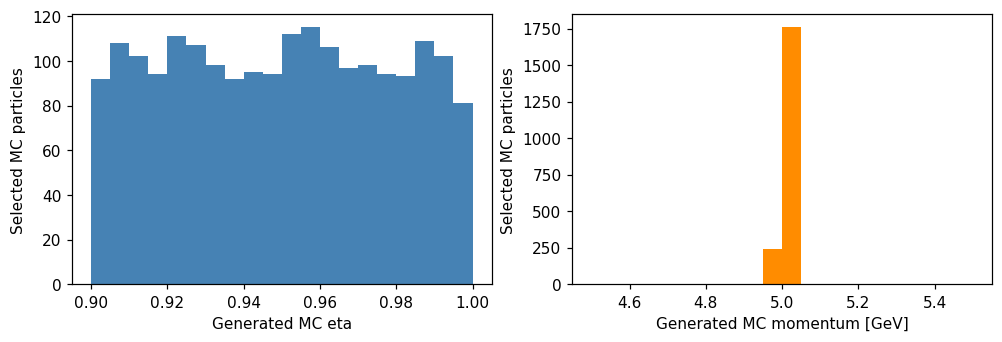

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3), layout='constrained')
axes[0].hist(particles.eta, bins=20, color='steelblue')
axes[0].set(xlabel='Generated MC eta', ylabel='Selected MC particles')
axes[1].hist(particles.p_GeV, bins=20, range=P_RANGE_GEV, color='darkorange')
axes[1].set(xlabel='Generated MC momentum [GeV]', ylabel='Selected MC particles')
plt.show()


## 3. Find the available tracking layers

Collections and CellID layouts are read from the file. The catalogue below
lists **observed hits in the selected MC sample**, not all possible geometry
surfaces. Several detectors reuse layer 0 or 1: always select the hit collection
and system as well. These are detector-layer groups, not ACTS surface IDs.
Decoded module/sensor fields retain finer segmentation; a missing encoded
layer is represented by NA, not an invented layer number.


In [5]:
catalogue = pd.DataFrame.from_dict(tables['metadata']['collections'], orient='index')
display(catalogue.rename_axis('collection').reset_index())
display(tables['surfaces'])
print('VertexBarrel CellID layout:', tables['metadata']['encodings'].get(IB_COLLECTION))


,collection,collection_id,type,subset
0,MCParticles,2714477136,edm4hep::MCParticleCollection,False
1,B0TrackerHits,1370106067,edm4hep::SimTrackerHitCollection,False
2,BackwardMPGDEndcapHits,3362963453,edm4hep::SimTrackerHitCollection,False
3,ForwardMPGDEndcapHits,3309489006,edm4hep::SimTrackerHitCollection,False
4,ForwardOffMTrackerHits,2451365843,edm4hep::SimTrackerHitCollection,False
5,ForwardRomanPotHits,1586770095,edm4hep::SimTrackerHitCollection,False
6,LumiSpecTrackerHits,4257345714,edm4hep::SimTrackerHitCollection,False
7,MPGDBarrelHits,2846270698,edm4hep::SimTrackerHitCollection,False
8,OuterMPGDBarrelHits,3679647107,edm4hep::SimTrackerHitCollection,False
9,SiBarrelHits,3062527592,edm4hep::SimTrackerHitCollection,False


,hit_collection,system,layer,n_hits,n_particles
0,MPGDBarrelHits,61,0,2049,1954
1,OuterMPGDBarrelHits,64,0,1594,1594
2,TOFBarrelHits,92,1,2044,1654
3,TrackerEndcapHits,77,1,1460,1460
4,TrackerEndcapHits,78,1,1167,1167
5,VertexBarrelHits,31,0,1826,1826
6,VertexBarrelHits,31,1,1824,1824
7,VertexBarrelHits,31,2,141,141


VertexBarrel CellID layout: system:0:8,layer:8:4,module:12:12,sensor:24:4,phi:32:-16,z:48:-16


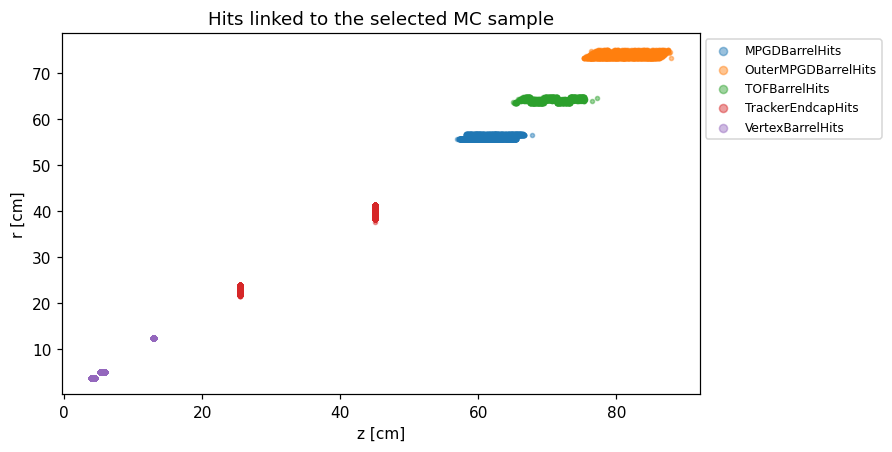

In [6]:
# All associated hit positions, coloured by collection. Coordinates are actual
# stored positions; no geometric extrapolation or fitted trajectory is drawn.
fig, ax = plt.subplots(figsize=(8, 4), layout='constrained')
for name, group in hits.groupby('hit_collection', observed=True):
    radius_cm = np.hypot(group.x_mm, group.y_mm)/10
    ax.scatter(group.z_mm/10, radius_cm, s=7, alpha=.45, label=name)
ax.set(xlabel='z [cm]', ylabel='r [cm]', title='Hits linked to the selected MC sample')
ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1, 1), markerscale=2)
plt.show()


## 4. Select all L0 hits with their complete information

This selection keeps every stored hit attribute: deposited energy [GeV],
time [ns], path length [mm], quality, position [mm], hit momentum [GeV],
CellID and original references. `cell_*` columns are decoded integer fields,
not physical positions. NA in those columns means that the readout does not
define that field. No first-hit choice or one-hit-per-layer assumption is made.


In [7]:
ib_hits = hits.loc[(hits.hit_collection == IB_COLLECTION) & (hits.system == IB_SYSTEM)]
l0_hits = ib_hits.loc[ib_hits.layer == 0]
print(f'L0: {len(l0_hits):,} hits from {len(l0_hits[KEY].drop_duplicates()):,} MC particles')
with pd.option_context('display.max_columns', None):
    display(l0_hits.head())

# Add truth kinematics for downstream plots/cuts only when needed.
l0_with_mc = l0_hits.merge(particles[KEY + ['p_GeV', 'eta', 'pdg']],
                          on=KEY, validate='many_to_one')
display(l0_with_mc[KEY + ['layer', 'eta', 'p_GeV', 'x_mm', 'y_mm', 'z_mm']].head())


L0: 1,826 hits from 1,826 MC particles


,cell_id,energy_deposit_GeV,time_ns,path_length_mm,quality,x_mm,y_mm,z_mm,px_GeV,py_GeV,pz_GeV,file_id,event_entry,mc_index,mc_collection_id,hit_collection,hit_collection_id,hit_index,system,layer,cell_module,cell_sensor,cell_x,cell_z,cell_slice,cell_y,cell_assembly,cell_sector,cell_strip,cell_phi,cell_segmentation_id,cell_idx,cell_idy,cell_ids
4191,11260412213706783,0.000008,0.189949,0.020946,0,-28.640769,-25.039493,42.329336,-2.509395,-2.206943,3.718705,1160063f-ec9f-4268-a2c5-04f17ab61ee8,0,0,2714477136,VertexBarrelHits,3497031840,0,31,0,92,6,<NA>,40,<NA>,<NA>,<NA>,<NA>,<NA>,329,<NA>,<NA>,<NA>,<NA>
4193,8446061878263839,0.000005,0.189439,0.020897,0,27.379898,26.412327,42.123640,2.403217,2.333227,3.711742,1160063f-ec9f-4268-a2c5-04f17ab61ee8,1,0,2714477136,VertexBarrelHits,3497031840,0,31,0,20,6,<NA>,30,<NA>,<NA>,<NA>,<NA>,<NA>,422,<NA>,<NA>,<NA>,<NA>
4195,23929277347381279,0.000012,0.192169,0.021189,0,-19.804725,-32.481421,43.219446,-1.712605,-2.824789,3.752893,1160063f-ec9f-4268-a2c5-04f17ab61ee8,2,0,2714477136,VertexBarrelHits,3497031840,0,31,0,92,12,<NA>,85,<NA>,<NA>,<NA>,<NA>,<NA>,909,<NA>,<NA>,<NA>,<NA>
4197,11260541062922271,0.000003,0.189958,0.020944,0,35.983371,-12.347747,42.333020,3.164182,-1.074937,3.718671,1160063f-ec9f-4268-a2c5-04f17ab61ee8,3,0,2714477136,VertexBarrelHits,3497031840,0,31,0,140,6,<NA>,40,<NA>,<NA>,<NA>,<NA>,<NA>,359,<NA>,<NA>,<NA>,<NA>
4199,24770974855741471,0.000010,0.183491,0.020235,0,-35.399777,13.932897,39.689497,-3.222215,1.257249,3.609343,1160063f-ec9f-4268-a2c5-04f17ab61ee8,4,0,2714477136,VertexBarrelHits,3497031840,0,31,0,68,5,<NA>,88,<NA>,<NA>,<NA>,<NA>,<NA>,274,<NA>,<NA>,<NA>,<NA>


,file_id,event_entry,mc_index,layer,eta,p_GeV,x_mm,y_mm,z_mm
0,1160063f-ec9f-4268-a2c5-04f17ab61ee8,0,0,0,0.958850,5.0,-28.640769,-25.039493,42.329336
1,1160063f-ec9f-4268-a2c5-04f17ab61ee8,1,0,0,0.955128,5.0,27.379898,26.412327,42.123640
2,1160063f-ec9f-4268-a2c5-04f17ab61ee8,2,0,0,0.974390,5.0,-19.804725,-32.481421,43.219446
3,1160063f-ec9f-4268-a2c5-04f17ab61ee8,3,0,0,0.958934,5.0,35.983371,-12.347747,42.333020
4,1160063f-ec9f-4268-a2c5-04f17ab61ee8,4,0,0,0.911613,5.0,-35.399777,13.932897,39.689497


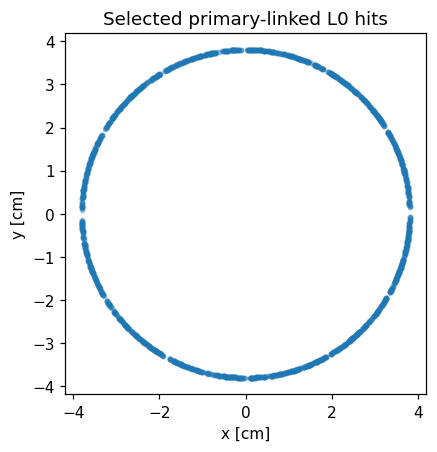

In [8]:
fig, ax = plt.subplots(figsize=(4.5, 4), layout='constrained')
ax.scatter(l0_hits.x_mm/10, l0_hits.y_mm/10, s=8, alpha=.35)
ax.set(xlabel='x [cm]', ylabel='y [cm]', title='Selected primary-linked L0 hits')
ax.set_aspect('equal')
plt.show()


## 5. Count L0/L1/L2 hits for every selected MC particle

Group hit rows by particle and layer, then reindex against **all selected MC
particles**. This supplies zero counts for missing layers and zero-hit particles.
The hit fraction below measures simulated hit presence, not track-reconstruction
efficiency. Distinct-particle counts and raw hit counts can differ.


L0  L1  L2
file_id                              event_entry mc_index            
1160063f-ec9f-4268-a2c5-04f17ab61ee8 0           0          1   1   0
                                     1           0          1   1   0
                                     2           0          1   1   0
                                     3           0          1   1   0
                                     4           0          1   1   0
                                     5           0          1   1   0
                                     6           0          1   1   0
                                     7           0          1   1   0
                                     8           0          1   0   0
                                     9           0          1   1   0

,selected_MC_particles,MC_with_hit,number_of_hits,fraction_with_hit
L0,2000,1826,1826,0.9130
L1,2000,1824,1824,0.9120
L2,2000,141,141,0.0705


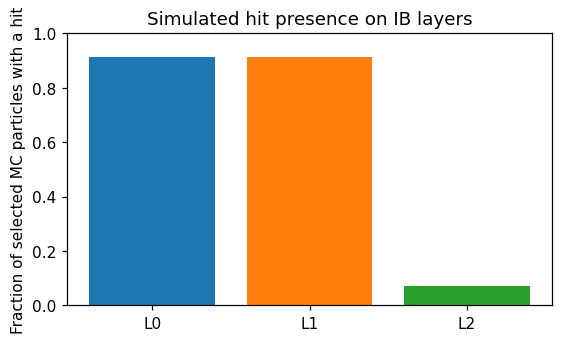

In [9]:
counts = ib_hits.groupby(KEY + ['layer'], observed=True).size().unstack('layer', fill_value=0)
counts = counts.reindex(index=pd.MultiIndex.from_frame(particles[KEY]),
                        columns=LAYER_IDS, fill_value=0)
counts.columns = [f'L{layer}' for layer in LAYER_IDS]
display(counts.head(10))

layer_summary = pd.DataFrame({
    'selected_MC_particles': len(particles),
    'MC_with_hit': (counts > 0).sum(),
    'number_of_hits': counts.sum(),
})
layer_summary['fraction_with_hit'] = layer_summary.MC_with_hit/len(particles)
display(layer_summary)
fig, ax = plt.subplots(figsize=(5, 3), layout='constrained')
ax.bar(layer_summary.index, layer_summary.fraction_with_hit, color=['C0', 'C1', 'C2'])
ax.set(ylabel='Fraction of selected MC particles with a hit', ylim=(0, 1),
       title='Simulated hit presence on IB layers')
plt.show()


## 6. Follow one MC particle through all its tracking hits

Choose `MC_ROW` in the input cell, then use its full key. The plots show only
stored hit positions; the markers do not define a propagated trajectory.
An absent marker does not establish whether the particle crossed active material.


,file_id,event_entry,mc_index,pdg,p_GeV,eta,n_hits
0,1160063f-ec9f-4268-a2c5-04f17ab61ee8,0,0,211,5.0,0.95885,5


,cell_id,energy_deposit_GeV,time_ns,path_length_mm,quality,x_mm,y_mm,z_mm,px_GeV,py_GeV,pz_GeV,file_id,event_entry,mc_index,mc_collection_id,hit_collection,hit_collection_id,hit_index,system,layer,cell_module,cell_sensor,cell_x,cell_z,cell_slice,cell_y,cell_assembly,cell_sector,cell_strip,cell_phi,cell_segmentation_id,cell_idx,cell_idy,cell_ids
0,18391293623556706365,5.881450e-07,2.837182,4.487403,0,-411.602799,-389.605791,630.627643,-2.330133,-2.396362,3.712324,1160063f-ec9f-4268-a2c5-04f17ab61ee8,0,0,2714477136,MPGDBarrelHits,2846270698,0,61,0,17,0,<NA>,-197,<NA>,<NA>,<NA>,<NA>,0,28,<NA>,<NA>,<NA>,<NA>
1,1280427959676588365,1.777196e-05,1.143507,0.053785,0,-170.215860,-153.222709,254.865000,-2.445041,-2.277954,3.717713,1160063f-ec9f-4268-a2c5-04f17ab61ee8,0,0,2714477136,TrackerEndcapHits,1948551886,0,77,1,5,1,-398,4548,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
2,2515537705056620878,1.170038e-05,2.018520,0.053789,0,-296.890557,-274.409506,449.865000,-2.385317,-2.340755,3.717303,1160063f-ec9f-4268-a2c5-04f17ab61ee8,0,0,2714477136,TrackerEndcapHits,1948551886,1,78,1,5,1,-969,8936,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
3,11260412213706783,7.516195e-06,0.189949,0.020946,0,-28.640769,-25.039493,42.329336,-2.509395,-2.206943,3.718705,1160063f-ec9f-4268-a2c5-04f17ab61ee8,0,0,2714477136,VertexBarrelHits,3497031840,0,31,0,92,6,<NA>,40,<NA>,<NA>,<NA>,<NA>,<NA>,329,<NA>,<NA>,<NA>,<NA>
4,3345947775263,7.460033e-06,0.251360,0.020947,0,-37.869693,-33.172348,56.017768,-2.504878,-2.211722,3.718871,1160063f-ec9f-4268-a2c5-04f17ab61ee8,0,0,2714477136,VertexBarrelHits,3497031840,1,31,1,117,10,<NA>,0,<NA>,<NA>,<NA>,<NA>,<NA>,779,<NA>,<NA>,<NA>,<NA>


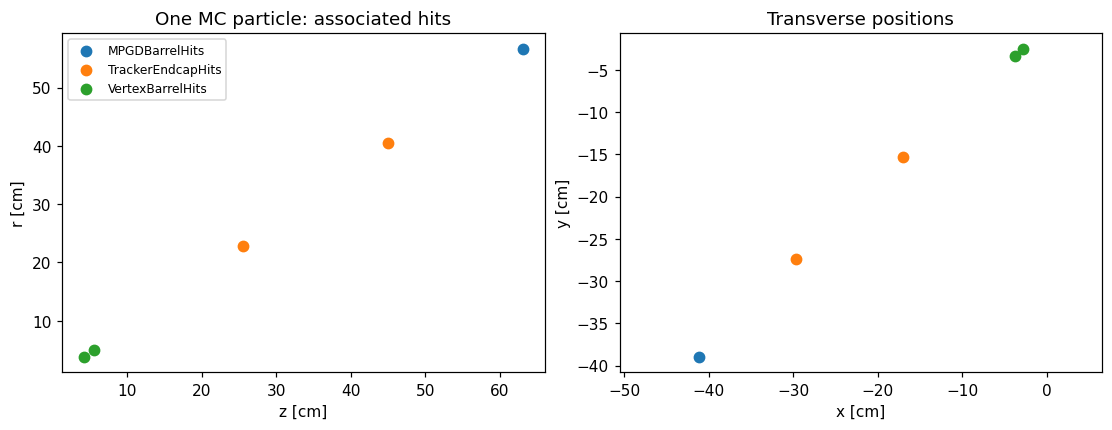

In [10]:
assert 0 <= MC_ROW < len(particles), 'Choose a valid MC_ROW in the input cell.'
one_particle = particles.iloc[[MC_ROW]]
one_hits = hits.merge(one_particle[KEY], on=KEY, validate='many_to_one')
display(one_particle[KEY + ['pdg', 'p_GeV', 'eta', 'n_hits']])
with pd.option_context('display.max_columns', None):
    display(one_hits)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout='constrained')
for name, group in one_hits.groupby('hit_collection', observed=True):
    radius_cm = np.hypot(group.x_mm, group.y_mm)/10
    axes[0].scatter(group.z_mm/10, radius_cm, s=45, label=name)
    axes[1].scatter(group.x_mm/10, group.y_mm/10, s=45)
axes[0].set(xlabel='z [cm]', ylabel='r [cm]', title='One MC particle: associated hits')
axes[1].set(xlabel='x [cm]', ylabel='y [cm]', title='Transverse positions')
axes[1].set_aspect('equal', adjustable='datalim')
if not one_hits.empty:
    axes[0].legend(fontsize=8)
plt.show()


## 7. Use the same operations in bounded-memory batch analysis

`read_mc_tracking_hits()` collects one file/prefix in memory. For large files,
iterate event blocks, make the same layer selections, accumulate counts or
histograms, and discard each block. Do not concatenate every file's raw hit table.
The check below rereads the same small prefix with a different block size and
requires identical particle/hit/layer counts.


In [11]:
stream_particles, stream_hits = 0, 0
stream_layer_hits = np.zeros(len(LAYER_IDS), dtype=np.int64)
for block in iter_mc_tracking_hits(ROOT_FILE, collections=COLLECTIONS, primary_only=True,
        pdgs=PDGS, eta_range=ETA_RANGE, p_range=P_RANGE_GEV,
        stop=STOP_EVENTS, step_size=137):
    stream_particles += len(block['particles'])
    stream_hits += len(block['hits'])
    selected = block['hits'].loc[(block['hits'].hit_collection == IB_COLLECTION)
                                & (block['hits'].system == IB_SYSTEM)]
    for index, layer in enumerate(LAYER_IDS):
        stream_layer_hits[index] += int((selected.layer == layer).sum())
assert stream_particles == len(particles) and stream_hits == len(hits)
np.testing.assert_array_equal(stream_layer_hits, counts.sum().to_numpy())
print('PASS: streaming counts match the collected tables with a different block size.')


PASS: streaming counts match the collected tables with a different block size.


## 8. Final consistency checks

These checks verify table integrity and unchanged input-file size/time. The
reader was also tested separately against independent PODIO object getters;
PODIO is not required to run this notebook.


In [12]:
HIT_KEY = ['file_id', 'event_entry', 'hit_collection_id', 'hit_index']
assert not particles.duplicated(KEY).any()
assert not hits.duplicated(HIT_KEY).any()
assert hits.cell_id.dtype == np.dtype('uint64')
assert len(hits.merge(particles[KEY], on=KEY, validate='many_to_one')) == len(hits)
assert particles.n_hits.sum() == len(hits)
assert len(counts) == len(particles)
assert len(one_hits) == int(one_particle.n_hits.iloc[0])
assert ROOT_FILE.stat().st_size == tables['metadata']['source_bytes']
assert ROOT_FILE.stat().st_mtime_ns == tables['metadata']['source_mtime_ns']
print('PASS: unique identities, valid MC links, exact CellIDs, hit totals and zero-hit rows.')
print(f'Validated {len(particles):,} MC particles and {len(hits):,} associated simulated hits.')


PASS: unique identities, valid MC links, exact CellIDs, hit totals and zero-hit rows.
Validated 2,000 MC particles and 12,105 associated simulated hits.
